# 🧬 Inference with Pretrained Models for Biodiversity Research

## iBOL 2026 | Hands-on Tutorial

Deep learning models are increasingly being used in biodiversity research to analyze biological data, including DNA barcodes and specimen images.

In this hands-on tutorial, the focus is on **using existing pretrained models rather than training models from scratch**. The goal is to learn how to prepare biological data, pass it through pretrained models, and use their outputs for downstream applications.


## 💻 Getting Started with Google Colab

Since this is a hands-on tutorial, you will be able to run the examples and experiment with pretrained models throughout the session.

[Google Colab](https://colab.research.google.com/) is a cloud-based environment that allows Python code to be written and executed directly in a web browser, without requiring local installation. It also provides access to computational resources, including GPUs.

**How does Colab work?**

A Colab notebook consists of two main types of cells:

- **Text cells:** Contain explanations, instructions, and visualizations.
- **Code cells:** Contain Python code that can be executed by clicking the ▶ button or pressing `Shift + Enter`.

**A note on computational resources:** Google Colab is convenient for learning and experimenting with pretrained models. However, for large-scale inference involving millions of samples, a local GPU or a dedicated cloud computing environment may be more suitable due to Colab's computational and runtime limitations.

## How Does Inference with a Pretrained Model Work?

Before getting started, let's look at the general workflow for using a pretrained model.

<img src="https://drive.google.com/thumbnail?id=1odpdlV9IVV6V1M9F8jRX52HSY4hwNwO1&sz=w1200" width="1000">

The process starts with **input data**, such as a text, a DNA sequence, or an image. The data is first **preprocessed** into the format expected by the model and then passed through the **pretrained model**.

The model produces numerical representations, called **embeddings**, which capture information learned during training. These embeddings can be used for downstream applications such as similarity search and classification.

## 🎯 Tutorial Overview

Throughout this tutorial, we will explore each step of this pipeline using pretrained models for DNA sequences and specimen images:

1. **Data preprocessing:** Prepare input data for the model.
2. **Loading pretrained models:** Load existing models and prepare them for inference.
3. **Embedding extraction:** Obtain numerical representations of the input data.
4. **Downstream applications:** Use model outputs for similarity search and classification.

By the end of the tutorial, you should have a basic understanding of how to use pretrained models for inference and how to adapt these workflows to your own biodiversity datasets.

## 🛠️ Prerequisites

- Basic familiarity with Python is helpful.
- No prior experience with deep learning is required.
- A Google account is needed to use Google Colab.
- No local installation is required.

**Let's get started!**

## Setup

### Installing Required Libraries

Before getting started, we need to install a few Python libraries that we will use throughout this tutorial.

We will use **PyTorch** for running pretrained models, **NumPy** and **Pandas** for working with data, **Matplotlib** for visualization, and **Pillow** for processing images.


In [ ]:
%pip install torch numpy pandas matplotlib pillow biopython

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 15.3 MB/s  0:00:00


In [ ]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from itertools import product

### Enable GPU (Optional)

We can check whether a GPU is available. Although a GPU is not required for all examples, it can significantly speed up model inference.

To enable GPU in Google Colab:

1. Go to **Runtime → Change runtime type**.
2. Select **T4 GPU** under Hardware accelerator.
3. Click **Save** and reconnect if needed.
4. Run the device checking cell below.

If the GPU is available, the output should be:

`Device: cuda`

Otherwise, the notebook will use the CPU:

`Device: cpu`

**Note:** Changing the runtime will restart your session, so you have to run the previous cells again.

In [ ]:
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', DEVICE)

Device: cuda


## Part I - DNA



### DNA Data Preparation

Before using a pretrained model, we need to prepare our data in a format that the model can understand. Different models require different types of input.

DNA sequences are represented using nucleotide characters (`A`, `C`, `G`, and `T`). However, deep learning models cannot directly process these characters as text. Instead, we need to convert DNA sequences into numerical representations. This process is called **tokenization**.

Different DNA language models use different tokenization strategies. In this tutorial, we will focus on one common approach which is **k-mer tokenization**, where a DNA sequence is divided into smaller subsequences of length k.



In [ ]:
seq = "NNNNATTTTATTTTTGGGGCTTGATCTGGAATAATTGGAACNNTTCATTAAGAATGTTAATTCGAGCAGA"
print(len(seq))

70


#### K-mer Tokenization

A **k-mer** is a DNA subsequence of length `k`. For example, consider the sequence:

`ACGTGCAATGCT`

Using `k = 4`, the sequence can be divided into non-overlapping k-mers:

`ACGT | GCAA | TGCT`

Once the sequence is divided into k-mers, each token needs to be converted into a numerical ID. This is done using a **vocabulary**, which maps each token to a unique integer.

<!-- Insert a figure here -->



Since DNA contains four standard nucleotides (`A`, `C`, `G`, and `T`), there are \(4^k\) possible k-mers. For example, with `k = 4`, there are \(4^4 = 256\) possible k-mers.

However, these integer IDs are not the numerical representations processed directly by the neural network. Instead, each ID is used as an **index into an embedding lookup table**, where it retrieves a learned embedding vector.

<!-- Insert embedding lookup table figure here -->

The ***embedding lookup table is part of the model***, and its vectors are learned during training. Therefore, **the tokenizer and vocabulary must match those used by the pretrained model**. Otherwise, the same token ID could refer to a different embedding vector, leading to incorrect representations.

We will now implement a simple k-mer tokenizer to demonstrate how DNA sequences are converted into token IDs.


<font color="#F70D1A">**Note**: This implementation is for teaching purposes only. In practice, always use the tokenizer provided with the pretrained model to ensure compatibility with its vocabulary and embedding lookup table.</font>

In [ ]:
class KmerTokenizer:
    def __init__(self, k=4):
        self.k = k

        self.special_tokens = ["[UNK]", "[CLS]"]

        # Generate all possible k-mers
        all_possible_kmers = ["".join(kmer) for kmer in product("ACGT", repeat=self.k)]

        # Build vocabulary
        tokens = self.special_tokens + all_possible_kmers
        self.vocab = {token: idx for idx, token in enumerate(tokens)}

    def tokenize(self, sequence):
        sequence = sequence.upper()
        kmers = [
            sequence[i:i + self.k]
            for i in range(0, len(sequence) - self.k + 1, self.k)
        ]
        return ["[CLS]"] + kmers

    def encode(self, sequence):
        return [
            self.vocab.get(kmer, self.special_tokens.index("[UNK]"))
            for kmer in self.tokenize(sequence)
        ]

    def __call__(self, sequence):
        return self.encode(sequence)

In [ ]:
tokenizer = KmerTokenizer(k=4)
tokenizer.vocab

{'[UNK]': 0,
 '[CLS]': 1,
 'AAAA': 2,
 'AAAC': 3,
 'AAAG': 4,
 'AAAT': 5,
 'AACA': 6,
 'AACC': 7,
 'AACG': 8,
 'AACT': 9,
 'AAGA': 10,
 'AAGC': 11,
 'AAGG': 12,
 'AAGT': 13,
 'AATA': 14,
 'AATC': 15,
 'AATG': 16,
 'AATT': 17,
 'ACAA': 18,
 'ACAC': 19,
 'ACAG': 20,
 'ACAT': 21,
 'ACCA': 22,
 'ACCC': 23,
 'ACCG': 24,
 'ACCT': 25,
 'ACGA': 26,
 'ACGC': 27,
 'ACGG': 28,
 'ACGT': 29,
 'ACTA': 30,
 'ACTC': 31,
 'ACTG': 32,
 'ACTT': 33,
 'AGAA': 34,
 'AGAC': 35,
 'AGAG': 36,
 'AGAT': 37,
 'AGCA': 38,
 'AGCC': 39,
 'AGCG': 40,
 'AGCT': 41,
 'AGGA': 42,
 'AGGC': 43,
 'AGGG': 44,
 'AGGT': 45,
 'AGTA': 46,
 'AGTC': 47,
 'AGTG': 48,
 'AGTT': 49,
 'ATAA': 50,
 'ATAC': 51,
 'ATAG': 52,
 'ATAT': 53,
 'ATCA': 54,
 'ATCC': 55,
 'ATCG': 56,
 'ATCT': 57,
 'ATGA': 58,
 'ATGC': 59,
 'ATGG': 60,
 'ATGT': 61,
 'ATTA': 62,
 'ATTC': 63,
 'ATTG': 64,
 'ATTT': 65,
 'CAAA': 66,
 'CAAC': 67,
 'CAAG': 68,
 'CAAT': 69,
 'CACA': 70,
 'CACC': 71,
 'CACG': 72,
 'CACT': 73,
 'CAGA': 74,
 'CAGC': 75,
 'CAGG': 76,
 'CAGT'

In [ ]:
print(seq)

tokens = tokenizer.tokenize(seq)
ids = tokenizer.encode(seq)

print(" ".join(f"{token:>6}" for token in tokens))
print(" ".join(f"{idx:>6}" for idx in ids))

NNNNATTTTATTTTTGGGGCTTGATCTGGAATAATTGGAACNNTTCATTAAGAATGTTAATTCGAGCAGA
 [CLS]   NNNN   ATTT   TATT   TTTG   GGGC   TTGA   TCTG   GAAT   AATT   GGAA   CNNT   TCAT   TAAG   AATG   TTAA   TTCG   AGCA
     1      0     65    209    256    171    250    224    133     17    162      0    213    196     16    242    248     38


##### Loading DNA Sequences from a FASTA File

We will download a DNA sequence from NCBI and follow three steps:

1. **Load the sequence:** Read the sequence id and nucleotide sequence from the FASTA file.
2. **Clean the sequence (optional):** Convert the sequence to uppercase and replace characters outside `ACGTN` with `N`.
3. **Tokenize the sequence:** Divide the cleaned sequence into k-mers and convert them into numerical IDs.


In [ ]:
import urllib.request

# Source: https://www.ncbi.nlm.nih.gov/nuccore/JQ601162.1

url = (
        "https://eutils.ncbi.nlm.nih.gov/entrez/eutils/efetch.fcgi?"
        "db=nuccore&id=JQ601162.1&rettype=fasta&retmode=text"
      )

urllib.request.urlretrieve(url, "barcode.fasta")

('barcode.fasta', <http.client.HTTPMessage at 0x7cdafbf2dbd0>)



> **Note:** The FASTA reader implemented below is a simplified example for demonstrating how DNA sequences can be loaded from a file. For real-world applications, especially when working with large datasets or multiple sequences, established libraries such as [Biopython](https://biopython.org/) provide more robust and optimized implementations.




In [ ]:
def clean_sequence(sequence):
    sequence = sequence.upper()
    valid_bases = "ACGTN"

    invalid_count = sum(base not in valid_bases for base in sequence)

    cleaned_sequence = "".join(
        base if base in valid_bases else "N"
        for base in sequence
    )

    if invalid_count > 0:
        print(f"Found {invalid_count} invalid characters. Replaced them with N.")

    return cleaned_sequence

In [ ]:
from Bio import SeqIO

record = SeqIO.read("barcode.fasta", "fasta")
seq = str(record.seq)

print(f"Sequence ID: {record.id}")
print(f"Sequence length: {len(seq)} bp")
print("Original sequence:", seq)
seq = clean_sequence(seq)

print("After cleaning:   ", seq)

tokens = tokenizer.tokenize(seq)
ids = tokenizer.encode(seq)

print(" ".join(f"{token:>6}" for token in tokens))
print(" ".join(f"{idx:>6}" for idx in ids))

Sequence ID: JQ601162.1
Sequence length: 636 bp
Original sequence: ACCTTATATTTANTCTTCGGAGCTTGAGCAGGAATAGTGGGGACAGCCCTAAGCATTATTATTCGAGCAGAACTAGGACAGCCTGGCACCTTACTTGGAGATGATCAAATCTATAACGTAGTAGTCACAGCACACGCATTTGTAATAATTTTCTTCATAGTTATACCTATAATAATTGGAGGATTTGGGAACTGACTAGTACCACTAATAATTGGAGCCCCAGATATAGCATTCCCACGAATAAATAATATAAGCTTCTGATTATTACCACCCTCATTTCTCCTACTTCTTGCATCATCCATAGTCGAAGCAGGAGCTGGGACCGGATGGACAGTTTACCCACCCCTAGCCGGTAACTTAGCTCATGCAGGAGCATCTGTAGACCTGACTATTTTCTCTCTACACCTAGCAGGAGTATCATCTATTTTAGGGGCTATTAATTTTATTACAACCATCATTAACATAAAACCACCAGCCATAACACAATATCAAACACCATTATTTGTATGATCAGTCCTAATTACAGCTGTACTACTACTTCTCTCATTACCAGTACTAGCCGCAGGTATCACTATATTATTAACAGACCGTAACCTTAACACAACTTTCTTTGACCCAGCNGGAGGGGGAGANCCT
After cleaning:    ACCTTATATTTANTCTTCGGAGCTTGAGCAGGAATAGTGGGGACAGCCCTAAGCATTATTATTCGAGCAGAACTAGGACAGCCTGGCACCTTACTTGGAGATGATCAAATCTATAACGTAGTAGTCACAGCACACGCATTTGTAATAATTTTCTTCATAGTTATACCTATAATAATTGGAGGATTTGGGAACTGACTAGTACCACTAATAATTGGAGCCCCAGATATAGCATTCCCACGAATAAATAATATAAGCTTCTGATTATTACCACCCTCAT

##### Loading DNA Sequences from a CSV File

DNA barcode datasets are also distributed as **CSV** files, where can contain additional information about each specimen, such as its taxonomic classification, collection location, and DNA barcode sequence.

In the following example, we will use a small portion of the data from the BIOSCAN dataset. In this metadata, we use the following columns:

- `processid`: The identifier associated with the specimen record.
- `nucleotides`: The raw DNA barcode sequence.

After loading the data, we will follow the same preprocessing steps as before.

In [ ]:
# !wget -O barcodes.tsv "https://huggingface.co/datasets/bioscan-ml/BIOSCAN-1M/resolve/main/BIOSCAN_Insect_Dataset_metadata.tsv"

In [ ]:
!pip -q install gdown

import gdown

DRIVE_URL = "https://drive.google.com/file/d/1yhRi7zaQAJh0A7TlQlO9mtej9Ozzjvw0/view?usp=sharing"

gdown.download(
    url=DRIVE_URL,
    output="barcode_tiny.csv",
    quiet=False,
    fuzzy=True
)

Downloading...
From: https://drive.google.com/uc?id=1yhRi7zaQAJh0A7TlQlO9mtej9Ozzjvw0
To: /content/barcode_tiny.csv
100%|██████████| 649k/649k [00:00<00:00, 73.8MB/s]


'barcode_tiny.csv'

In [ ]:
df = pd.read_csv("barcode_tiny.csv", sep=",")

seq_id = df.iloc[0]["processid"]
seq = df.iloc[0]["nucleotides"]

print("Sequence ID:", seq_id)
print("Original sequence:", seq)

seq = clean_sequence(seq)

print("After cleaning:   ", seq)

tokens = tokenizer.tokenize(seq)
ids = tokenizer.encode(seq)

print(" ".join(f"{token:>6}" for token in tokens))
print(" ".join(f"{idx:>6}" for idx in ids))

Sequence ID: JSMAY486-11
Original sequence: TTCATTATATTTTATTTTTGGAGCTTGATCGGGAATAGTTGGAACATCTTTAAGAATACTAATCCGAGCAGAATTAGGACATCCTGGAACATTTATTGGAGATGATCAAATTTATAACGTAATTGTAACAGCTCACGCTTTTATTATAATTTTTTTTATAGTTATACCTATTTTAATTGGAGGGTTTGGAAATTGATTATTGCCTTTAATATTAGGAGCCCCTGACATAGCATTTCCTCGAATAAATAATATAAGATTTTGACTATTACCCCCCTCTCTTTCACTTCTTCTTTCAAGTAGAATCGTAGAAAATGGGGCAGGAACCGGTTGAACGGTTTATCCCCCCCTATCTTCAAGAATTGCTCATAGAGGAGCATCAGTTGATTTAGCTATTTTTTCCCTTCATCTTGCAGGAATTTCTTCAATTTTAGGATCTGTAAATTTTATTACAACTGCAATTAATATACGATCAAATGGGATTACATTAGATCGAATACCTCTATTTGTATGATCAGTCATTATTACAACTATTTTGTTGCTTCTATCTTTACCTGTATTAGCAGGAGCAATTACAATGCTTCTCACAGACCGAAATTTAAATACTTCTTTTTTTGATCCTGCTGGAGGAGGAGATCCAATTCTATACCAACATTTATTT
After cleaning:    TTCATTATATTTTATTTTTGGAGCTTGATCGGGAATAGTTGGAACATCTTTAAGAATACTAATCCGAGCAGAATTAGGACATCCTGGAACATTTATTGGAGATGATCAAATTTATAACGTAATTGTAACAGCTCACGCTTTTATTATAATTTTTTTTATAGTTATACCTATTTTAATTGGAGGGTTTGGAAATTGATTATTGCCTTTAATATTAGGAGCCCCTGACATAGCATTTCCTCGAATAAATAATATAAGATTTTGACTATTACCCCCCTCTC

#### Other Tokenization Strategies

K-mer tokenization is just one approach to representing DNA sequences. Other commonly used strategies include:

- **Character-level tokenization (`k = 1`):** Each nucleotide is treated as an individual token.
- **Byte Pair Encoding (BPE):** A tokenization method that learns a vocabulary of variable-length tokens from training sequences.

Different pretrained DNA models may use different tokenization strategies. **When using a pretrained model, it is important to use its associated tokenizer and vocabulary**, rather than the simplified tokenizer implemented in this tutorial.

### Loading a Pretrained DNA Model

One of the easiest ways to access pretrained models is through **[Hugging Face](https://huggingface.co/)**, a platform that hosts a wide range of models for different types of data, including text, images, and DNA sequences. You can explore the available models on the [Hugging Face Model Hub](https://huggingface.co/models).


Several pretrained DNA language models are available on Hugging Face. These models have been trained on large collections of DNA sequences and can be used to extract numerical representations (embeddings) from new sequences.

Here are a few examples:

| Model | Description | Hugging Face |
|---|---|---|
| **BarcodeBERT** | A language model pretrained on DNA barcode sequences | [BarcodeBERT](https://huggingface.co/bioscan-ml/BarcodeBERT) |
| **DNABERT-2** | A DNA foundation model trained on genomic sequences from multiple species | [DNABERT-2](https://huggingface.co/zhihan1996/DNABERT-2-117M) |
| **Nucleotide Transformer** | A family of DNA language models pretrained on genomic sequences | [Nucleotide Transformer](https://huggingface.co/InstaDeepAI/nucleotide-transformer-500m-human-ref) |
| **HyenaDNA** | A genomic sequence model designed to process long DNA sequences | [HyenaDNA](https://huggingface.co/LongSafari/hyenadna-small-32k-seqlen-hf) |

For this tutorial, we will load **BarcodeBERT** pretrained model as an example, tokenize the DNA sequence we prepared earlier, and pass it through the model to extract its numerical representations (embeddings).

In [ ]:
from transformers import AutoTokenizer, AutoModelForTokenClassification

model_name = "bioscan-ml/BarcodeBERT"

tokenizer = AutoTokenizer.from_pretrained(
    model_name, trust_remote_code=True
)

model = AutoModelForTokenClassification.from_pretrained(
    model_name, trust_remote_code=True
)

model = model.to(DEVICE)

# Switches the model to evaluation mode, disabling training-specific behavior
model.eval()

print(model)

Loading weights:   0%|          | 0/71 [00:00<?, ?it/s]

BertForTokenClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(258, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-3): 4 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-12, elemen

In [ ]:
# Use the DNA sequence loaded earlier
print("DNA sequence:", seq)

# Tokenize the DNA sequence
inputs = tokenizer(seq, return_tensors="pt")
print("Tokenized sequence", inputs['input_ids'])

# Ensure the inputs have a batch dimension
inputs = {
    key: value.unsqueeze(0) if value.ndim == 1 else value
    for key, value in inputs.items()
}

# Move tensors to the same device as the model
inputs = {
    key: value.to(DEVICE)
    for key, value in inputs.items()
}

print("Shape of the tokenized sequence", inputs['input_ids'].shape)

print("\nData is now ready for inference!\n")

with torch.no_grad(): # Keep this line to save memory usage (no gradient is calculated)
    outputs = model(**inputs, output_hidden_states=True)

# Extract numerical representations from the last hidden layer
hidden_states = outputs.hidden_states[-1]

print("Embedding shape before pooling:", hidden_states.shape)

# Mean pooling to obtain one embedding per sequence
attention_mask = inputs["attention_mask"].unsqueeze(-1)

embedding = (
    (hidden_states * attention_mask).sum(dim=1)
    / attention_mask.sum(dim=1).clamp(min=1)
)

print("Embedding shape after pooling: ", embedding.shape)

embedding = embedding.cpu().numpy()

print("First 20 values:", embedding[0,:20])

DNA sequence: TTCATTATATTTTATTTTTGGAGCTTGATCGGGAATAGTTGGAACATCTTTAAGAATACTAATCCGAGCAGAATTAGGACATCCTGGAACATTTATTGGAGATGATCAAATTTATAACGTAATTGTAACAGCTCACGCTTTTATTATAATTTTTTTTATAGTTATACCTATTTTAATTGGAGGGTTTGGAAATTGATTATTGCCTTTAATATTAGGAGCCCCTGACATAGCATTTCCTCGAATAAATAATATAAGATTTTGACTATTACCCCCCTCTCTTTCACTTCTTCTTTCAAGTAGAATCGTAGAAAATGGGGCAGGAACCGGTTGAACGGTTTATCCCCCCCTATCTTCAAGAATTGCTCATAGAGGAGCATCAGTTGATTTAGCTATTTTTTCCCTTCATCTTGCAGGAATTTCTTCAATTTTAGGATCTGTAAATTTTATTACAACTGCAATTAATATACGATCAAATGGGATTACATTAGATCGAATACCTCTATTTGTATGATCAGTCATTATTACAACTATTTTGTTGCTTCTATCTTTACCTGTATTAGCAGGAGCAATTACAATGCTTCTCACAGACCGAAATTTAAATACTTCTTTTTTTGATCCTGCTGGAGGAGGAGATCCAATTCTATACCAACATTTATTT
Tokenized sequence tensor([246, 245,  65, 209, 256, 139, 250, 220, 133,  49, 162,  79, 254,  34,
        201,  15, 100,  74,  62, 163,  55, 234,  21, 245, 234, 144,  54,  17,
        206,  29,  17, 178,  75, 211, 161, 245, 206,  65, 257, 206, 190, 199,
        209, 242, 252,  44, 256, 130, 250, 245, 231, 254,  53, 204,  39,  

### Applications of DNA Embeddings

#### DNA Sequence Similarity

Pretrained DNA language models offer an alignment-free approach to determine the similarity of DNA sequences. The models will convert DNA sequences into **embeddings**, and then we can compare them using cosine similarity.

**Our goal:** Explore whether sequences that are more similar at the nucleotide level also have more similar embeddings.


In [ ]:
# Use the barcode_tiny dataset downloaded earlier
df = pd.read_csv("barcode_tiny.csv")

# Find a family with at least two distinct specimens
family_counts = df.groupby(["order_name", "family_name"])["processid"].nunique()

order1, family1 = family_counts[family_counts >= 2].index[0]

# Select two specimens from the same family
same_family = (
    df[(df["order_name"] == order1) & (df["family_name"] == family1)]
    .drop_duplicates(subset="processid")
    .iloc[:2]
)

# Select one specimen from a different order
different_order = df[df["order_name"] != order1].iloc[[0]]

selected = pd.concat([same_family, different_order]).reset_index(drop=True)

selected["Sample"] = ["S1", "S2", "S3"]

sequences = dict(zip(selected["Sample"], selected["nucleotides"]))

display(
    selected[["Sample", "processid", "order_name", "family_name"]]
)

for name, sequence in sequences.items():
    print(f"{name}: {sequence[:80]}...")

,Sample,processid,order_name,family_name
0,S1,SSFDB1531-14,Coleoptera,Carabidae
1,S2,BBCCM238-10,Coleoptera,Carabidae
2,S3,JSMAY486-11,Diptera,Chironomidae


S1: ACTTTATATTTTATTTTTGGTGCATGAGCAGGAATAGTAGGAACTTCATTAAGTATACTAATTCGAGCTGAATTAGGAAA...
S2: AACTTTATATTTTATTTTTGGTGCTTGAGCAGGAATAGTAGGAACTTCTTTAAGAATACTAATTCGAACTGAATTAGGAA...
S3: TTCATTATATTTTATTTTTGGAGCTTGATCGGGAATAGTTGGAACATCTTTAAGAATACTAATCCGAGCAGAATTAGGAC...


In [ ]:
from Bio.Align import PairwiseAligner

aligner = PairwiseAligner()
aligner.mode = "global"
aligner.match_score = 2
aligner.mismatch_score = -1
aligner.open_gap_score = -5
aligner.extend_gap_score = -0.5

def nucleotide_similarity(seq1, seq2):
    alignment = aligner.align(seq1, seq2)[0]

    # Count matching nucleotides and aligned positions
    counts = alignment.counts()

    matches = counts.identities
    alignment_length = (
        counts.identities + counts.mismatches + counts.gaps
    )

    return 100 * matches / alignment_length if alignment_length else 0

results = []

for name1, name2 in [("S1", "S2"), ("S1", "S3")]:
    similarity = nucleotide_similarity(sequences[name1], sequences[name2])

    results.append({
        "Sequence 1": name1,
        "Sequence 2": name2,
        "Nucleotide Identity (%)": similarity
    })

similarity_df = pd.DataFrame(results)

display(similarity_df.round(2))

,Sequence 1,Sequence 2,Nucleotide Identity (%)
0,S1,S2,78.12
1,S1,S3,68.24


In [ ]:
sequence_names = list(sequences.keys())
sequence_list = list(sequences.values())

# Tokenize individually, then batch
tokenized = [
    tokenizer(seq, return_tensors="pt", padding=True)
    for seq in sequence_list
]

# Combine into a batch
inputs = {
    key: torch.stack([item[key].reshape(-1) for item in tokenized]).to(DEVICE)
    for key in tokenized[0]
}

# Single forward pass
with torch.no_grad():
    outputs = model(**inputs, output_hidden_states=True)

hidden_states = outputs.hidden_states[-1]

# Mean pooling (excluding padding tokens)
mask = inputs["attention_mask"].unsqueeze(-1)
embeddings = (hidden_states * mask).sum(dim=1) / mask.sum(dim=1)

embeddings = embeddings.cpu().numpy()

print("Embeddings shape:", embeddings.shape)

Embeddings shape: (3, 768)


In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

similarity_matrix = cosine_similarity(embeddings)

comparison = similarity_df.copy()

comparison["Embedding Cosine Similarity"] = [
    similarity_matrix[
        sequence_names.index(row["Sequence 1"]),
        sequence_names.index(row["Sequence 2"])
    ]
    for _, row in comparison.iterrows()
]

display(comparison.round(3))

,Sequence 1,Sequence 2,Nucleotide Identity (%),Embedding Cosine Similarity
0,S1,S2,78.116,0.916
1,S1,S3,68.237,0.263




---


> **Key takeaway: Once embeddings have been extracted, we can compare sequences using vector similarity rather than performing pairwise alignments. However, embedding similarity should not be interpreted as percentage sequence identity.**



---



#### Searching a DNA Barcode Database

Imagine we have a database containing multiple DNA barcodes. Given a new DNA sequence, how can we find the most similar sequences in our database?

Instead of comparing the query against every sequence using traditional alignment, we can use a pretrained DNA language model to represent each sequence as an **embedding**. We can then perform a similarity search using cosine similarity.

**Our goal:** Demonstrate how pretrained DNA embeddings can support efficient similarity search and potentially help identify unknown specimens.



In [ ]:
database_df = pd.read_csv("barcode_tiny.csv")

columns = [
    "processid", "order_name", "family_name", "genus_name",
    "species_name", "nucleotides", "sequence_len"
]

display(database_df[columns].head(100))

,processid,order_name,family_name,genus_name,species_name,nucleotides,sequence_len
0,JSMAY486-11,Diptera,Chironomidae,Micropsectra,Micropsectra polita,TTCATTATATTTTATTTTTGGAGCTTGATCGGGAATAGTTGGAACA...,658
1,SMTPF8723-14,Diptera,Chironomidae,Micropsectra,Micropsectra subletteorum,CTCTCTATATTTTATTTTTGGAGCCTGATCCGGTATAATTGGCACT...,632
2,CNGBC133-13,Diptera,Chironomidae,Micropsectra,Micropsectra subletteorum,GCTCTTTATATTTTATTTTTGGGGCCTGATCCGGTATAATTGGCAC...,590
3,SMTPB20006-13,Diptera,Chironomidae,Micropsectra,Micropsectra subletteorum,NNNNNNNNNNTTTATTTTTGGAGCCTGATCCGGTATAATTGGCACT...,634
4,CNGBK820-14,Diptera,Chironomidae,Micropsectra,Micropsectra subletteorum,GCTCTTTATATTTTATTTTTGGGGCCTGATCCGGTATAATTGGCAC...,588
...,...,...,...,...,...,...,...
95,CNTMA420-14,Diptera,Sciaridae,Cratyna,Cratyna longispina,CAAGAATAGTGGGAACCTCTTTAAGAATATTAATTCGTGCAGAATT...,550
96,CNTNH1457-14,Diptera,Sciaridae,Cratyna,Cratyna longispina,TTTATTTTTGGGGCTTGATCAAGAATAGTGGGAACCTCTTTAAGAA...,603
97,CNPKJ1671-14,Diptera,Sciaridae,Cratyna,Cratyna longispina,ACATTATATTTTATTTTTGGAGCTTGATCAAGAATAGTGGGAACCT...,588
98,CNPKJ384-14,Diptera,Sciaridae,Cratyna,Cratyna longispina,GTACATTATATTTTATTTTTGGGGCTTGATCAAGAATAGTGGGAAC...,563


In [ ]:
DRIVE_URL = "https://drive.google.com/file/d/1QasaeXLcMUmrM8VxZd6mqp4yunxbBWBU/view?usp=sharing"

gdown.download(
    url=DRIVE_URL,
    output="query.csv",
    quiet=False,
    fuzzy=True
)

query_df = pd.read_csv("query.csv")

display(query_df[columns].head())

Downloading...
From: https://drive.google.com/uc?id=1QasaeXLcMUmrM8VxZd6mqp4yunxbBWBU
To: /content/query.csv
100%|██████████| 872/872 [00:00<00:00, 3.76MB/s]


,processid,order_name,family_name,genus_name,species_name,nucleotides,sequence_len
0,SMTPP2893-15,Hymenoptera,Braconidae,Ephedrus,Ephedrus helleni,TTATGAGCTGGTATAGTTGGTATATCTTTAAGTTTATTAATTCGTA...,636


In [ ]:
import torch.nn.functional as F

def extract_embeddings(sequences, batch_size=32):
    all_embeddings = []
    model.eval()

    for start in range(0, len(sequences), batch_size):
        batch = sequences[start:start + batch_size]

        # BarcodeBERT tokenizer expects one sequence at a time
        tokenized = [
            tokenizer(
                seq,
                return_tensors="pt",
                padding="max_length",
                truncation=True
            )
            for seq in batch
        ]

        # Combine individually tokenized sequences into a batch
        inputs = {
            key: torch.stack([item[key].reshape(-1) for item in tokenized]).to(DEVICE)
            for key in tokenized[0]
        }

        with torch.no_grad():
            outputs = model(**inputs, output_hidden_states=True)

        hidden_states = outputs.hidden_states[-1]

        # Mean pooling, consistent with Application 1
        mask = inputs["attention_mask"].unsqueeze(-1)

        embeddings = (
            (hidden_states * mask).sum(dim=1)
            / mask.sum(dim=1).clamp(min=1)
        )

        all_embeddings.append(embeddings.cpu())

    return torch.cat(all_embeddings, dim=0)


# Extract embeddings
database_embeddings = extract_embeddings(
    database_df["nucleotides"].tolist()
)

query_embeddings = extract_embeddings(
    query_df["nucleotides"].tolist()
)

print("Database embeddings:", database_embeddings.shape)
print("Query embeddings:", query_embeddings.shape)


Database embeddings: torch.Size([900, 768])
Query embeddings: torch.Size([1, 768])


In [ ]:
# Normalize embeddings
database_normalized = F.normalize(database_embeddings, p=2, dim=1)
query_normalized = F.normalize(query_embeddings, p=2, dim=1)

# Cosine similarity: (num_queries, num_database_samples)
similarity_matrix = query_normalized @ database_normalized.T

# Find best match for the query
best_scores, best_indices = similarity_matrix.max(dim=1)

# Retrieve matching database records
best_matches = database_df.iloc[best_indices.numpy()].copy()
best_matches = best_matches.reset_index(drop=True)

# Add query information and similarity scores
best_matches.insert(
    0, "query_processid",
    query_df["processid"].values
)

best_matches["cosine_similarity"] = best_scores.numpy()

# Display results
result_columns = [
    "processid", "order_name",
    "family_name", "genus_name", "species_name",
    "cosine_similarity"
]

print("Query:")
display(query_df[columns].head())

print("\n\nBest match:")
display(best_matches[result_columns].round(4))


Query:


,processid,order_name,family_name,genus_name,species_name,nucleotides,sequence_len
0,SMTPP2893-15,Hymenoptera,Braconidae,Ephedrus,Ephedrus helleni,TTATGAGCTGGTATAGTTGGTATATCTTTAAGTTTATTAATTCGTA...,636




Best match:


,processid,order_name,family_name,genus_name,species_name,cosine_similarity
0,ASWAV745-08,Hymenoptera,Braconidae,Ephedrus,Ephedrus lacertosus,0.9111


In [ ]:
query_idx = 0
top_k = 5

scores, indices = torch.topk(
    similarity_matrix[query_idx],
    k=min(top_k, len(database_df))
)

top_matches = database_df.iloc[indices.numpy()].copy()

top_matches["cosine_similarity"] = scores.numpy()


print("Query:")
display(query_df[columns].head())

print(f"\n\nTop {top_k} matches:")
display(
    top_matches[
        ["processid", "order_name", "family_name",
         "genus_name", "species_name", "cosine_similarity"]
    ].round(4)
)


Query:


,processid,order_name,family_name,genus_name,species_name,nucleotides,sequence_len
0,SMTPP2893-15,Hymenoptera,Braconidae,Ephedrus,Ephedrus helleni,TTATGAGCTGGTATAGTTGGTATATCTTTAAGTTTATTAATTCGTA...,636




Top 5 matches:


,processid,order_name,family_name,genus_name,species_name,cosine_similarity
227,ASWAV745-08,Hymenoptera,Braconidae,Ephedrus,Ephedrus lacertosus,0.9111
228,SSJAD5343-13,Hymenoptera,Braconidae,Ephedrus,Ephedrus lacertosus,0.9013
225,SSBAB2448-12,Hymenoptera,Braconidae,Ephedrus,Ephedrus lacertosus,0.8803
226,SSWLC1110-13,Hymenoptera,Braconidae,Ephedrus,Ephedrus lacertosus,0.8753
229,CNKLF1781-15,Hymenoptera,Braconidae,Ephedrus,Ephedrus lacertosus,0.8600




---



> Key takeaway: DNA embeddings can be used to search a reference database and identify the most similar sequences using vector similarity metrics. Some pretrained models may generate more informative and generalizable representations, potentially leading to higher retrieval accuracy.




---



#### DNA Barcode Classification Using K-Nearest Neighbors (KNN)

Can we use DNA embeddings to **predict the taxonomic family of unknown DNA barcodes**?

One simple approach is **K-Nearest Neighbors (KNN)**. Instead of relying on a single similar sequence, KNN considers the K most similar sequences in the reference database and predicts the family using majority voting.

**Our goal:** Use pretrained DNA embeddings to classify approximately 50 query sequences at the family level and evaluate the classification accuracy.



In [ ]:
DRIVE_URL = "https://drive.google.com/file/d/1Sw3MHQNHsul_VACYsXgjBykW6PlvcL1D/view?usp=sharing"

gdown.download(
    url=DRIVE_URL,
    output="queries_100.csv",
    quiet=False,
    fuzzy=True
)

# Load the query dataset
queries_df = pd.read_csv("queries_100.csv")

# Display the query sequences and their known labels
display(queries_df[
    ["processid", "family_name", "nucleotides"]
].head())

Downloading...
From: https://drive.google.com/uc?id=1Sw3MHQNHsul_VACYsXgjBykW6PlvcL1D
To: /content/queries_100.csv
100%|██████████| 71.2k/71.2k [00:00<00:00, 54.8MB/s]


,processid,family_name,nucleotides
0,SMTPI8888-14,Vespidae,AGATTAATTATTCGTCTAGAATTAGGTACACCTTTATCAATTATTA...
1,TMNBB317-06,Noctuidae,AACATTATATTTTATTTTTGGAATTTGAGCAGGAATAGTAGGAACT...
2,SSPAC7086-13,Elateridae,NACTTTATACTTCATCTTTGGTGCTTGAGCAGGAATGCTAGGTACA...
3,SSEIB11770-13,Syrphidae,NACATTATATTTTTTATTTGGTGCTTGAGCTGGTATAGTAGGAACC...
4,PHDIP1304-11,Syrphidae,AACTTTATATTTTNTATTTGGAACCTGAGCTGGAATAGTAGGTACA...


In [ ]:
# Extract embeddings
queries_embeddings = extract_embeddings(
    queries_df["nucleotides"].tolist()
)

print("Database embeddings:", database_embeddings.shape)
print("Queries embeddings:", queries_embeddings.shape)

Database embeddings: torch.Size([900, 768])
Queries embeddings: torch.Size([100, 768])


In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Convert embeddings to NumPy arrays
reference_embeddings = database_embeddings.detach().cpu().numpy()
queries_embeddings = queries_embeddings.detach().cpu().numpy()

# Initialize KNN
k = 1

knn = KNeighborsClassifier(
    n_neighbors=k,
    metric="cosine",
    weights="uniform"
)

# Fit KNN using the reference database
knn.fit(
    reference_embeddings,
    database_df["family_name"]
)

# Predict the family of each query
predicted_families = knn.predict(queries_embeddings)

In [ ]:
# Create a results table
results = pd.DataFrame({
    "process_id": queries_df["processid"],
    "actual_family": queries_df["family_name"],
    "predicted_family": predicted_families
})

# Calculate accuracy
accuracy = accuracy_score(
    results["actual_family"],
    results["predicted_family"]
)

print(f"Family-level KNN accuracy (K={k}): {accuracy:.2%}")

display(results)

Family-level KNN accuracy (K=1): 77.00%


,process_id,actual_family,predicted_family
0,SMTPI8888-14,Vespidae,Vespidae
1,TMNBB317-06,Noctuidae,Noctuidae
2,SSPAC7086-13,Elateridae,Elateridae
3,SSEIB11770-13,Syrphidae,Syrphidae
4,PHDIP1304-11,Syrphidae,Syrphidae
...,...,...,...
95,CNYOC1761-15,Tortricidae,Tortricidae
96,CNBRN019-14,Elateridae,Elateridae
97,SSKUB6344-15,Cicadellidae,Apidae
98,JSHYN895-11,Megachilidae,Megachilidae


---

> **Key takeaway:** Pretrained DNA embeddings can be used for taxonomic classification. By finding the nearest neighbors of a query sequence in a reference database, KNN predicts its family based on the labels of similar DNA barcodes. Classification accuracy provides a simple way to evaluate how well these embeddings capture taxonomic relationships.

---

#### Visualizing Taxonomic Relationships

We can explore the taxonomic relationships between species by visualizing DNA barcode embeddings using
**t-SNE**.

**Our goal:** Explore whether DNA barcodes belonging to the same taxonomic groups form clusters in the embedding space.

(300, 768)


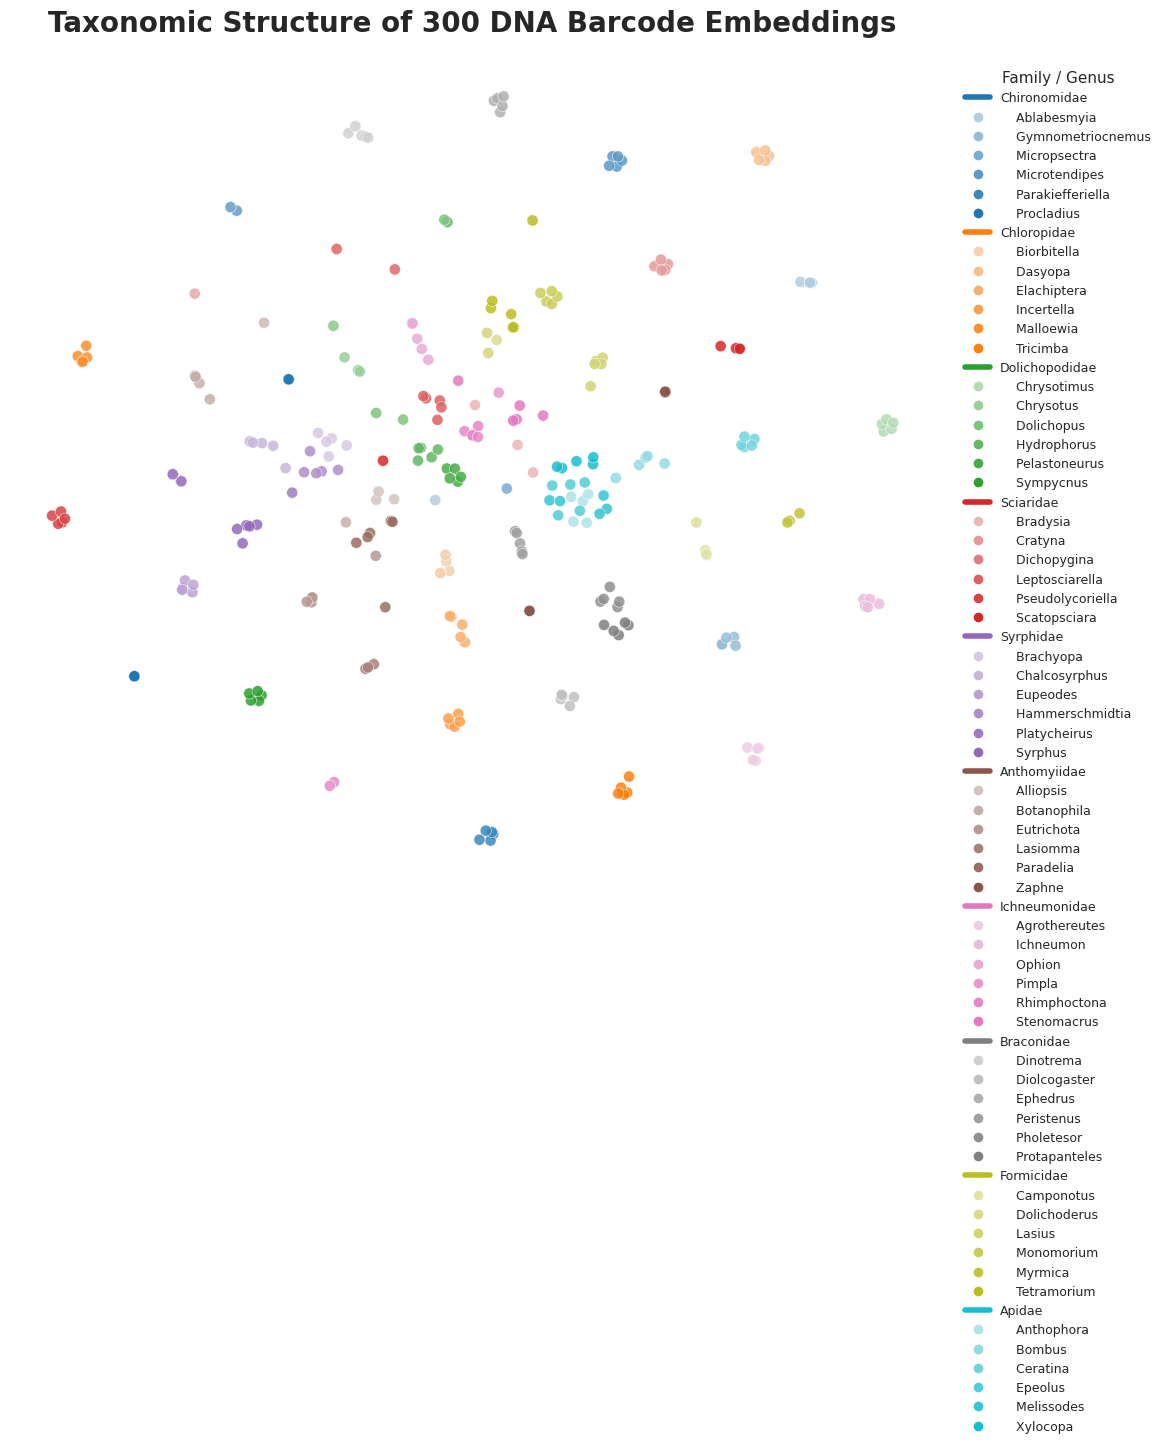

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE
from matplotlib.lines import Line2D

# --------------------------------------------------
# 1. Select the 10 most common families
# --------------------------------------------------

top_families = database_df["family_name"].value_counts().head(10).index

mask = database_df["family_name"].isin(top_families).to_numpy()

taxonomy = database_df.loc[mask, ["family_name", "genus_name"]
                           ].reset_index(drop=True)

embeddings = np.asarray(database_embeddings.cpu())[mask]

print(embeddings.shape)

# --------------------------------------------------
# 2. Compute t-SNE
# --------------------------------------------------

tsne = TSNE(
    n_components=2,
    perplexity=min(30, (len(embeddings) - 1) / 3),
    init="pca",
    learning_rate="auto",
    random_state=42
)

embeddings_2d = tsne.fit_transform(embeddings)

# --------------------------------------------------
# 3. Hierarchical colors: Family → Genus
# --------------------------------------------------

families = list(top_families)

# Distinct colors for the 10 families
family_colors = dict(zip(
    families,
    sns.color_palette("tab10", len(families))
))

genus_colors = {}

for family in families:
    genera = sorted(
        taxonomy.loc[
            taxonomy["family_name"] == family,
            "genus_name"
        ].unique()
    )

    # Light-to-dark shades of the family color
    shades = sns.light_palette(
        family_colors[family],
        n_colors=len(genera) + 2
    )[2:]

    for genus, shade in zip(genera, shades):
        genus_colors[(family, genus)] = shade

point_colors = [
    genus_colors[(family, genus)]
    for family, genus in zip(
        taxonomy["family_name"],
        taxonomy["genus_name"]
    )
]

# --------------------------------------------------
# 4. Plot t-SNE
# --------------------------------------------------

sns.set_theme(style="white", context="talk")

fig, ax = plt.subplots(figsize=(12, 13))

ax.scatter(
    embeddings_2d[:, 0],
    embeddings_2d[:, 1],
    c=point_colors,
    s=65,
    alpha=0.85,
    edgecolors="white",
    linewidths=0.4,
    rasterized=True
)

ax.set_title(
    f"Taxonomic Structure of {len(taxonomy)} DNA Barcode Embeddings",
    fontsize=20,
    fontweight="bold",
    pad=20
)

# ax.set_xlabel("t-SNE 1", fontsize=13)
# ax.set_ylabel("t-SNE 2", fontsize=13)

ax.set_xticks([])
ax.set_yticks([])

sns.despine(ax=ax, left=True, bottom=True)

# --------------------------------------------------
# 5. Hierarchical legend: Family → Genus
# --------------------------------------------------

handles = []

for family in families:

    # Family heading
    handles.append(
        Line2D(
            [], [],
            color=family_colors[family],
            linewidth=4,
            label=family
        )
    )

    genera = sorted(
        taxonomy.loc[
            taxonomy["family_name"] == family,
            "genus_name"
        ].unique()
    )

    for genus in genera:
        handles.append(
            Line2D(
                [], [],
                marker="o",
                linestyle="None",
                markerfacecolor=genus_colors[(family, genus)],
                markeredgecolor="white",
                markersize=8,
                label=f"    {genus}"
            )
        )

ax.legend(
    handles=handles,
    title="Family / Genus",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False,
    fontsize=9,
    title_fontsize=11
)

plt.tight_layout()
plt.savefig("taxonomy.png", dpi=300)
plt.show()



---


> **Key takeaway:** Pretrained DNA language models can capture biological patterns in their embedding space.
> **Note:** t-SNE is an exploratory visualization. The distances between clusters should not be interpreted as evolutionary distances.



---



## Part II - Image

### Image Data Preparation

Similar to DNA sequences, images need to be preprocessed before being passed to a pretrained model.

Image preprocessing typically involves:

1. **Loading the image:** Read an image from a file or URL.
2. **Resizing:** Adjust the image dimensions to match the model's expected input size (e.g., 224 × 224 pixels).
3. **Rescaling:** Convert pixel values from [0, 255] to [0, 1].
4. **Normalization:** Normalize pixel values using the mean and standard deviation expected by the model.
5. **Converting to tensors:** Convert the image into a PyTorch tensor with shape (channels, height, width).

Different pretrained vision models may require different preprocessing steps and parameters. Therefore, it is recommended to use the image processor associated with each pretrained model whenever possible.

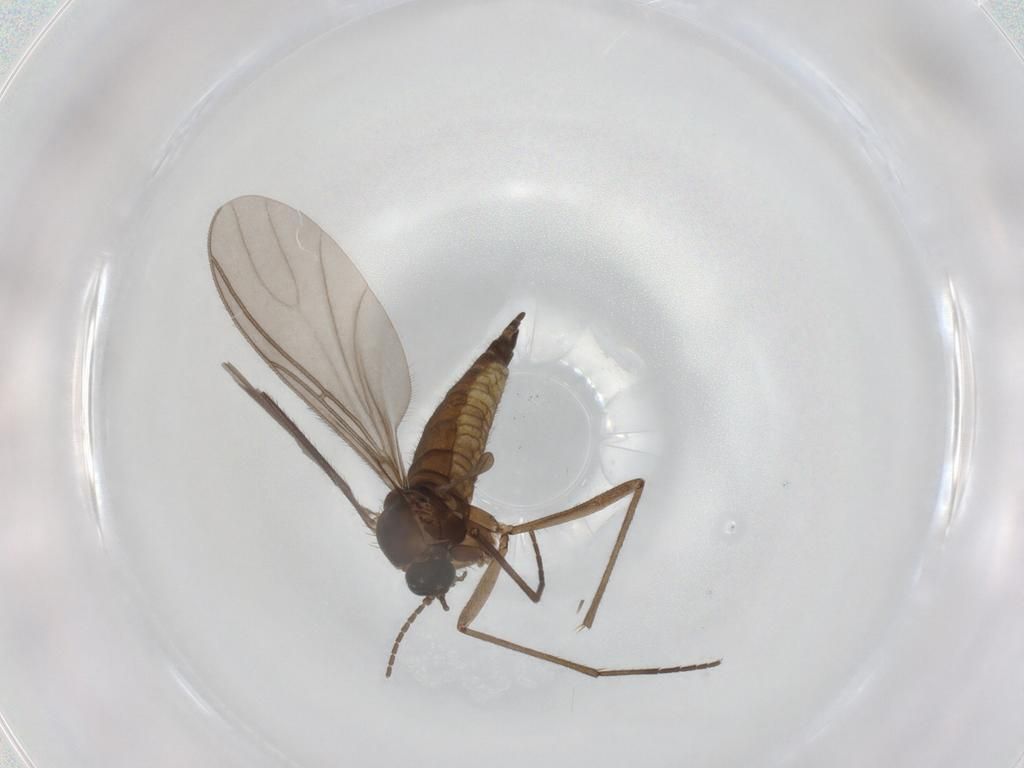

In [ ]:
# https://browser.bioscan-ml.org/


import requests
from PIL import Image
from IPython.display import display

url = "https://annotations2.cs.sfu.ca/data/bioscan/bioscan5m/images/original_full/train/3/THAMF11663-23.jpg"

response = requests.get(url)
response.raise_for_status()

with open("bioscan_image.jpg", "wb") as f:
    f.write(response.content)

display(Image.open("bioscan_image.jpg"))

In [ ]:
# Load an image
image = Image.open("bioscan_image.jpg").convert("RGB")

print("Original image size:", image.size)

# Center crop to a square using the smallest dimension
width, height = image.size
crop_size = min(width, height)

left = (width - crop_size) // 2
top = (height - crop_size) // 2

image = image.crop((left, top, left + crop_size, top + crop_size))

# Resize to 224 x 224
image = image.resize((224, 224))

# Convert to a NumPy array and rescale pixels to [0, 1]
image_array = np.array(image) / 255.0

# Normalize pixels to [-1, 1]
image_array = (image_array - 0.5) / 0.5

# Convert to a PyTorch tensor (channels, height, width)
image_tensor = torch.tensor(image_array, dtype=torch.float32)
image_tensor = image_tensor.permute(2, 0, 1)

print("Image tensor shape:", image_tensor.shape)
print("Pixel value range:", image_tensor.min().item(), image_tensor.max().item())

Original image size: (1024, 768)
Image tensor shape: torch.Size([3, 224, 224])
Pixel value range: -0.8117647171020508 0.9529411792755127


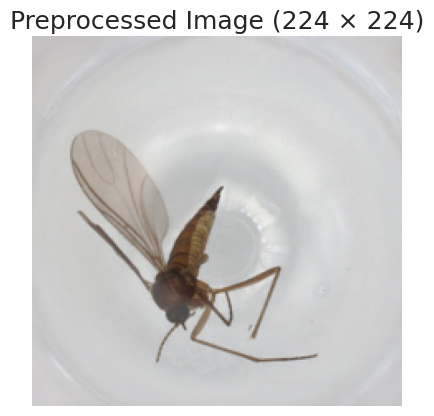

In [ ]:
import matplotlib.pyplot as plt

# Convert tensor back to an image for visualization
processed_image = image_tensor.permute(1, 2, 0).numpy()
processed_image = (processed_image + 1) / 2

# Visualize the preprocessed image
plt.imshow(processed_image)
plt.title("Preprocessed Image (224 × 224)")
plt.axis("off")
plt.show()

### Loading a Pretrained Image Model

Similar to DNA language models, pretrained image models can convert an image into a numerical embedding. These embeddings represent visual features learned during pretraining and can later be used for tasks such as image similarity search.

Here, we use Vision Transformer [(ViT)](https://huggingface.co/google/vit-base-patch16-224), pretrained on ImageNet. The image processor prepares the input using the model's expected resizing, rescaling, and normalization. ViT divides the image into patches and processes them with transformer layers. We extract the final `[CLS]` token representation as a single embedding for the entire image, rather than predicting an ImageNet class.

In [ ]:
from transformers import ViTImageProcessor, ViTForImageClassification

# Load the pretrained image processor and feature-extraction model
image_model_name = "google/vit-base-patch16-224"
image_processor = ViTImageProcessor.from_pretrained(image_model_name)
image_model = ViTForImageClassification.from_pretrained(image_model_name).to(DEVICE)
image_model.eval()  # Disable training-specific behavior

# Use the BIOSCAN image downloaded earlier
image = Image.open("bioscan_image.jpg").convert("RGB")

# Apply the model's required preprocessing and add a batch dimension
image_inputs = image_processor(images=image, return_tensors="pt")
image_inputs = {key: value.to(DEVICE) for key, value in image_inputs.items()}
print("Image input shape:", image_inputs["pixel_values"].shape)

# Run inference and return hidden states from all transformer layers
with torch.no_grad():
    image_outputs = image_model(**image_inputs, output_hidden_states=True)

# Extract the final hidden state
last_hidden_state = image_outputs.hidden_states[-1]

# Extract the [CLS] token as the image embedding
image_embedding = last_hidden_state[:, 0, :].cpu().numpy()

print("Embedding shape:", image_embedding.shape)
print("First 20 values:", image_embedding[0, :20])

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Image input shape: torch.Size([1, 3, 224, 224])
Embedding shape: (1, 768)
First 20 values: [-3.984229   5.97439   -3.0537817  1.3155572 -3.7726073  5.552039
 -4.793226  -2.9619796 -3.2719483 -0.8713908  4.341568   5.2336826
  3.9806912 -6.482545   7.145494  -0.4429357  4.249161  -3.1149936
 -2.735609  -2.629385 ]


## Part III - Multimodal Pretrained Models

### Image Text Pair

[BioCLIP](https://huggingface.co/imageomics/bioclip)  is a vision-language model trained on biological images and their taxonomic information. Unlike conventional image classification models, BioCLIP can compare images with text descriptions in a shared embedding space.

Our goal: Given an image of an organism and several candidate taxonomic labels, identify which label best matches the image.

In [ ]:
%pip -q install open_clip_torch

import open_clip

model, _, preprocess = open_clip.create_model_and_transforms(
    "hf-hub:imageomics/bioclip"
)

text_tokenizer = open_clip.get_tokenizer(
    "hf-hub:imageomics/bioclip"
)

model = model.to(DEVICE)
model.eval()

open_clip_config.json:   0%|          | 0.00/469 [00:00<?, ?B/s]

open_clip_pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  599MB            

open_clip_pytorch_model.bin: downloading bytes:           |  0.00B            

CLIP(
  (visual): VisionTransformer(
    (conv1): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16), bias=False)
    (patch_dropout): Identity()
    (ln_pre): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
    (transformer): Transformer(
      (resblocks): ModuleList(
        (0-11): 12 x ResidualAttentionBlock(
          (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
          (attn): MultiheadAttention(
            (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
          )
          (ls_1): Identity()
          (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
          (mlp): Sequential(
            (c_fc): Linear(in_features=768, out_features=3072, bias=True)
            (gelu): GELU(approximate='none')
            (c_proj): Linear(in_features=3072, out_features=768, bias=True)
          )
          (ls_2): Identity()
        )
      )
    )
    (ln_post): LayerNorm((768,), eps=1e-05, elementwise_affine

In [ ]:
image = Image.open("bioscan_image.jpg").convert("RGB")
image_input = preprocess(image).unsqueeze(0).to(DEVICE)

candidate_order_labels = [
    "Diptera",
    "Hymenoptera",
    "Lepidoptera",
    "Coleoptera",
    "Hemiptera"
]

descriptions = [
    f"a photo of an organism in the order {label}"
    for label in candidate_labels
]

text_inputs = text_tokenizer(descriptions).to(DEVICE)

In [ ]:
with torch.no_grad():
    image_embedding = model.encode_image(image_input)
    text_embeddings = model.encode_text(text_inputs)

image_embedding = F.normalize(image_embedding, dim=-1)
text_embeddings = F.normalize(text_embeddings, dim=-1)

similarities = (
    image_embedding @ text_embeddings.T
).squeeze(0)

results = pd.DataFrame({
    "Taxonomic Order": candidate_order_labels,
    "Cosine Similarity": similarities.cpu().numpy()
}).sort_values("Cosine Similarity", ascending=False)

display(results)

print("\nPredicted order:", results.iloc[0]["Taxonomic Order"])

,Taxonomic Order,Cosine Similarity
0,Diptera,0.040996
1,Hymenoptera,0.021711
4,Hemiptera,0.010087
3,Coleoptera,-0.001026
2,Lepidoptera,-0.019762



Predicted order: Diptera


### DNA Image Pair
Similarly, multimodal models such as [CLIBD](https://huggingface.co/bioscan-ml/clibd) learn to map **DNA sequences and images into a shared embedding space**, allowing us to compare them directly.

For example, given a **DNA barcode and a collection of specimen images**, we can identify which image is most likely associated with the DNA sequence. Conversely, given **an image and a database of DNA barcodes**, we can retrieve the DNA sequences that are most similar to the image in the shared embedding space.

This opens up new possibilities for biodiversity analysis by connecting different types of biological data, even when only one modality is available for a query.